Loading images...
Loaded 400 images.
Computing PCA...


Visualizing eigenfaces...


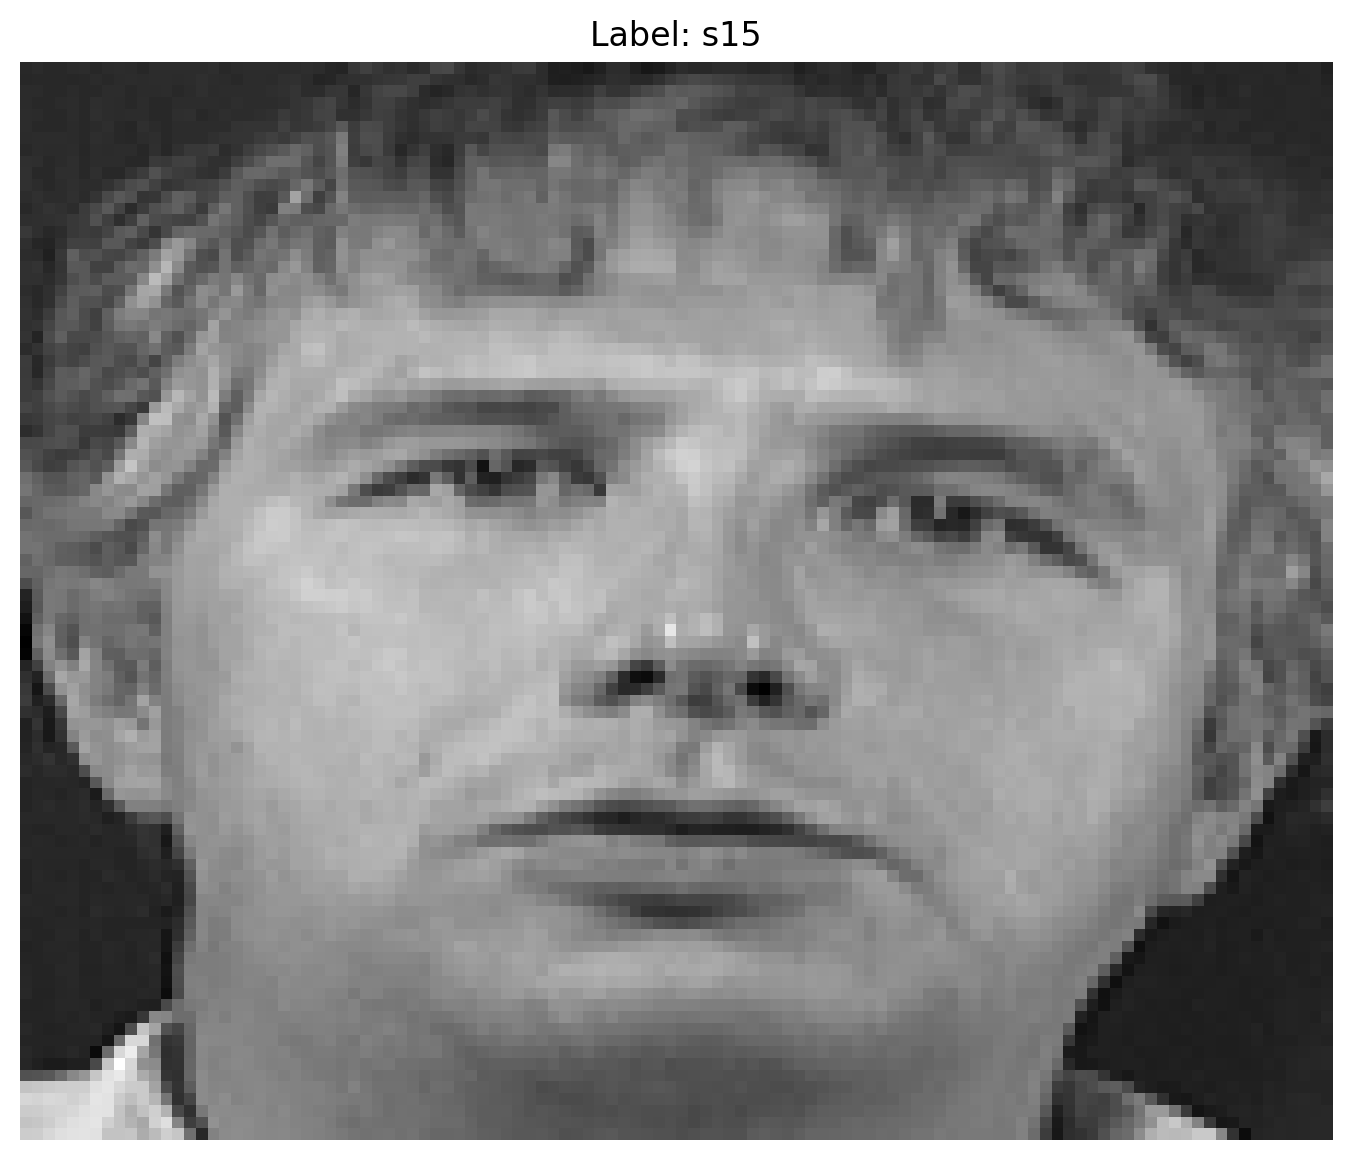

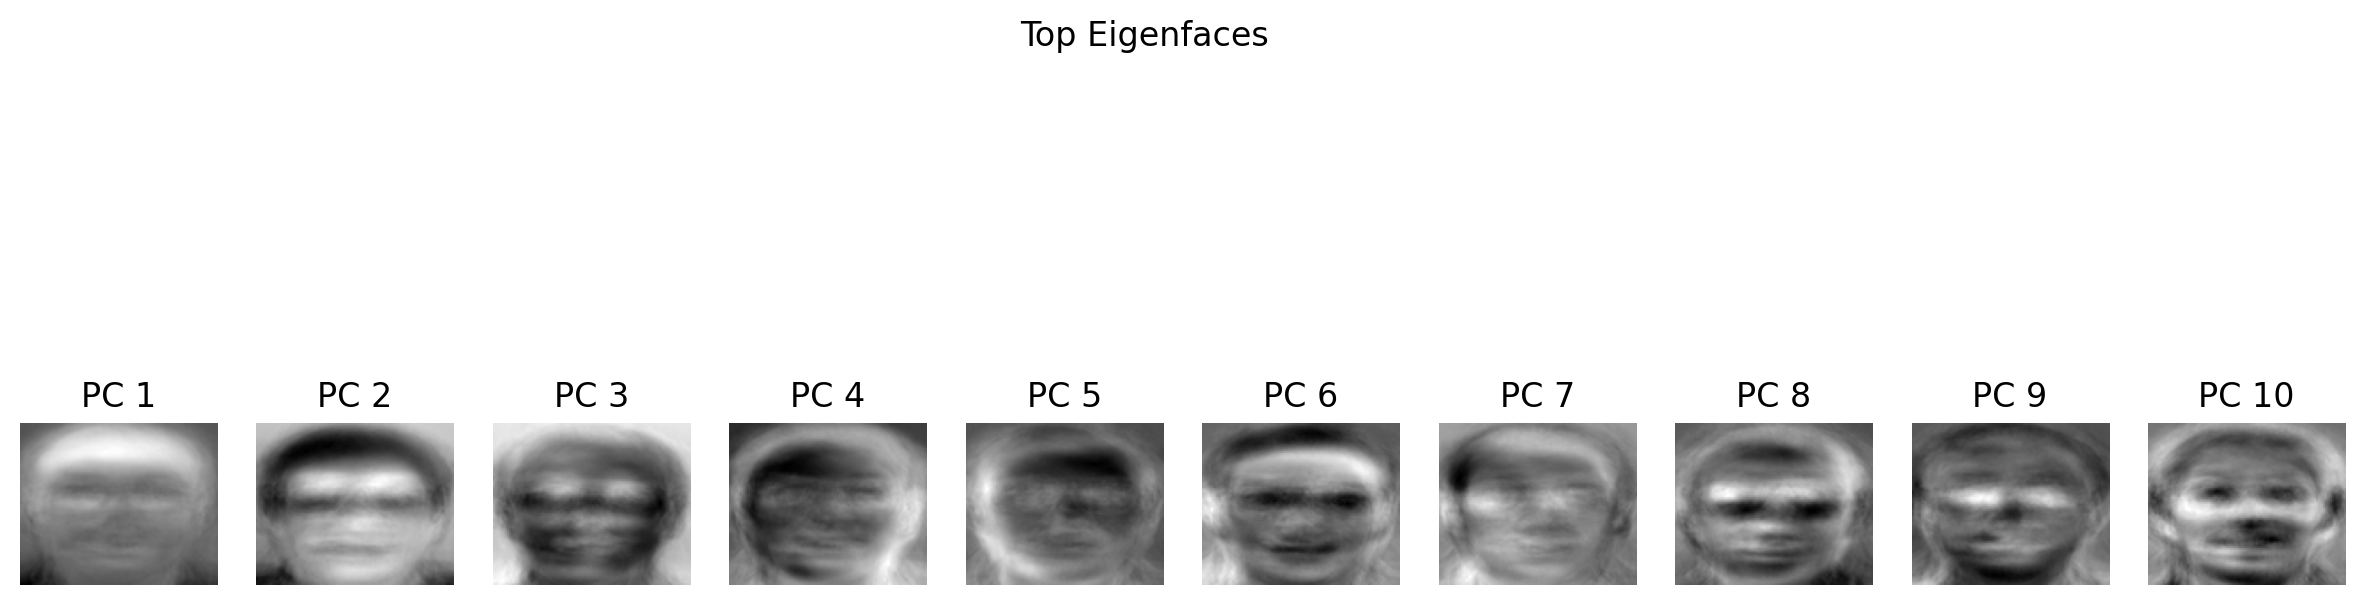

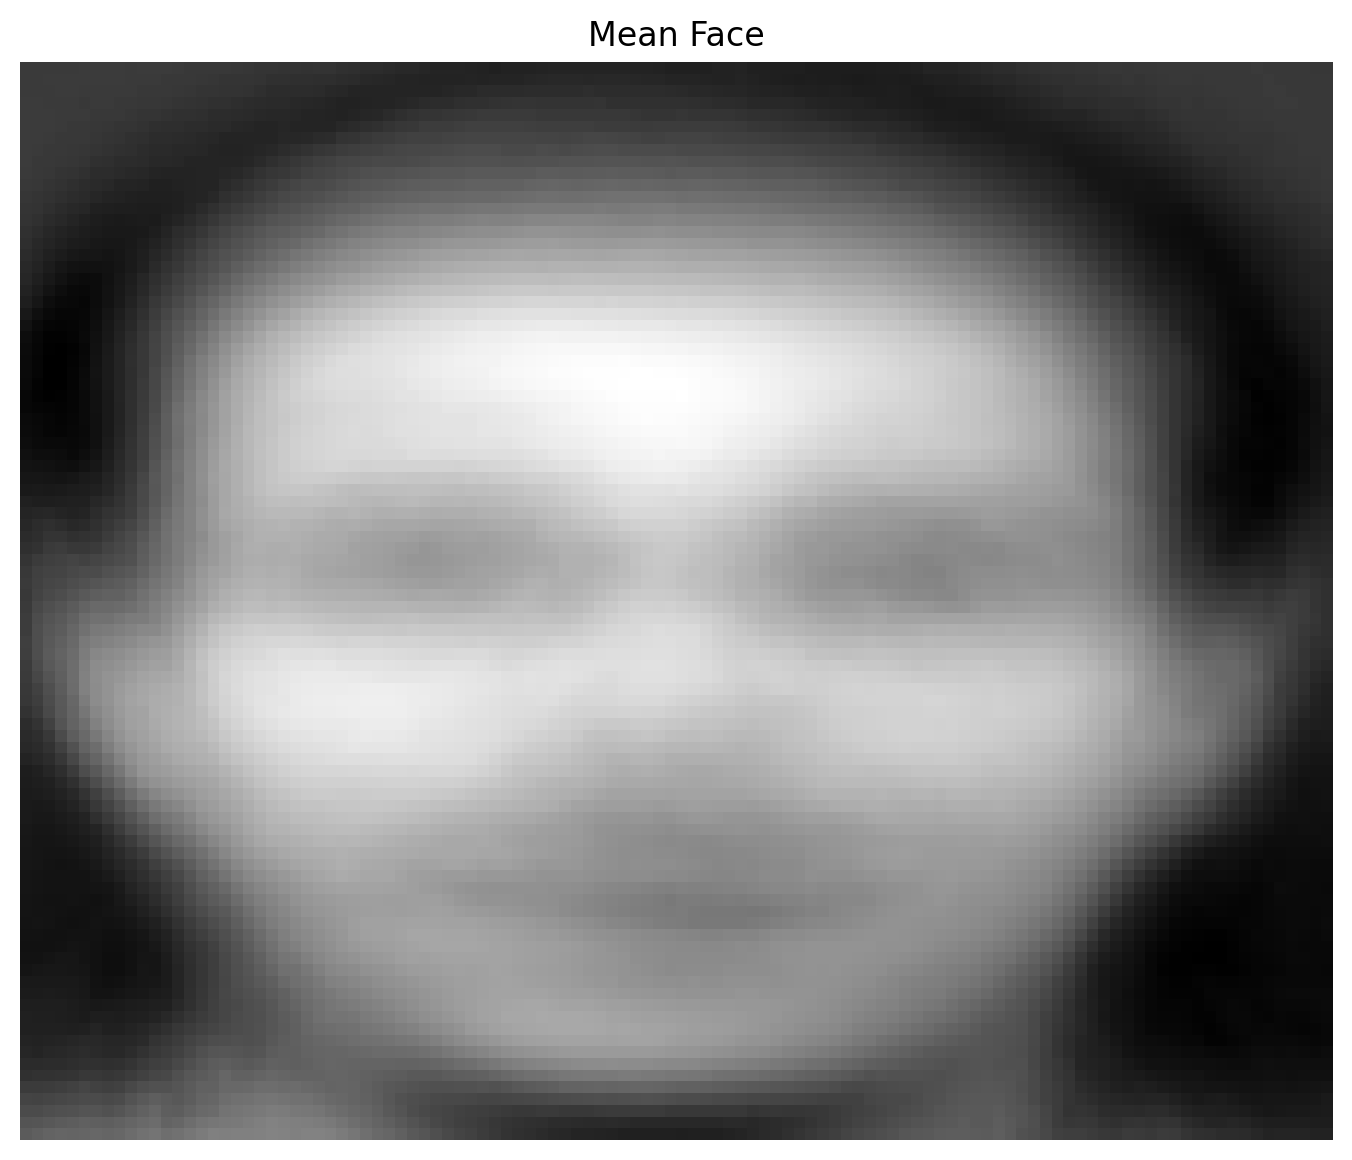

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --- Configuration ---
DATASET_PATH = "./att_faces"  # e.g., "./att_faces"
IMAGE_SIZE = (112, 92)
NUM_EIGENFACES = 25


# --- Load Images ---
def load_images(dataset_path):
    images = []
    labels = []
    for person_dir in os.listdir(dataset_path):
        person_path = os.path.join(dataset_path, person_dir)
        if os.path.isdir(person_path):
            for filename in os.listdir(person_path):
                img_path = os.path.join(person_path, filename)
                img = Image.open(img_path).convert('L')  # Convert to grayscale
                img = img.resize(IMAGE_SIZE)
                images.append(np.asarray(img, dtype=np.float32).flatten())
                labels.append(person_dir)
    return np.array(images), labels


# --- Compute PCA ---
def compute_eigenfaces(images, num_components):
    scaler = StandardScaler(with_std=False)
    images_centered = scaler.fit_transform(images)
    pca = PCA(n_components=num_components,
              svd_solver='randomized',
              whiten=True)
    pca.fit(images_centered)
    return pca, scaler.mean_


# --- Visualize Eigenfaces ---
def plot_eigenfaces(pca, image_shape, num_faces=10):
    fig, axes = plt.subplots(1, num_faces, figsize=(15, 5))
    for i in range(num_faces):
        axes[i].imshow(pca.components_[i].reshape(image_shape[1],
                                                  image_shape[0]),
                       cmap='gray')
        axes[i].axis('off')
        axes[i].set_title(f"PC {i+1}")
    plt.suptitle("Top Eigenfaces")
    plt.show()


# --- Main Execution ---
if __name__ == "__main__":
    print("Loading images...")
    images, labels = load_images(DATASET_PATH)
    print(f"Loaded {len(images)} images.")

    # Reshape and plot the first image
    first_image = images[0].reshape(IMAGE_SIZE[1],
                                    IMAGE_SIZE[0])  # height x width
    plt.imshow(first_image, cmap='gray')
    plt.title(f"Label: {labels[0]}")
    plt.axis('off')

    print("Computing PCA...")
    pca, mean_face = compute_eigenfaces(images, NUM_EIGENFACES)

    print("Visualizing eigenfaces...")
    plot_eigenfaces(pca, IMAGE_SIZE, num_faces=10)

    # Optional: Visualize mean face
    plt.imshow(mean_face.reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap='gray')
    plt.title("Mean Face")
    plt.axis('off')
    plt.show()